# Inspect the SMARTS noise-source flags

A quick way to open and explore the two public tables that go with
`smarts_noise_source_note.md`:

- **per source** (1,719 rows): `smarts_noise_sources.csv`, next to this notebook;
- **per file** (1,000,000 rows): `smarts_noise_source_flags.csv.gz`, on the Data_Vault drive under
  `extracted/release_note/` (skipped cleanly if the drive is unplugged).

Every column is documented in Section 4 of the note. Rebuild the tables with
`tools/audit/smarts_release_products.py`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 40, "display.width", 200)

NOTE_DIR = Path.cwd()   # run from docs/smarts_release_note/
DATA_ROOT = Path(os.environ.get("SMARTS_DATA_ROOT", "/Volumes/Data_Vault/smarts_data"))
FILES_CSV = DATA_ROOT / "extracted" / "release_note" / "smarts_noise_source_flags.csv.gz"
print("per-file table available:", FILES_CSV.exists())

per-file table available: True


## Per-source table

In [2]:
src = pd.read_csv(NOTE_DIR / "smarts_noise_sources.csv")
print(src.shape)
src.head()

(1719, 30)


,noise_tic,noise_lc_file,classification,periodic,P_ref_d,ls_P1_d,ls_P1_power,ls_P1_amp_ppm,ab_persistent,ls_periodic,search_detected,search_P_d,cm_retained,near_lmc,has_corrupted_segment,n_files,ra_deg,dec_deg,Tmag,d_lmc_deg,n_gaia_nb,n_gaia_nb_bright,n_gaia_nb_var,gaia_nb_var_classes,ffi_check,ffi_lc_authors,ffi_sectors,ffi_match,ffi_n_sectors_matching,ffi_n_sectors
0,10000241253,TIC10000241253_full.lc.fits,quiet,False,NaN,19.9624,0.009283,124.1810,True,False,False,NaN,0.967179,False,False,813,60.0771,-67.8068,13.263,7.73902,1.0,0.0,0.0,NaN,not_tested,NaN,NaN,NaN,NaN,NaN
1,10000241254,TIC10000241254_full.lc.fits,quiet,False,NaN,31.2398,0.016907,83.6492,True,False,False,NaN,0.428676,False,False,708,59.9156,-67.6389,11.090,7.86464,2.0,0.0,0.0,NaN,not_tested,NaN,NaN,NaN,NaN,NaN
2,10000241266,TIC10000241266_full.lc.fits,quiet,False,NaN,14.1008,0.010362,410.1030,True,False,False,NaN,0.122259,False,False,780,59.9887,-66.1520,14.928,8.57796,1.0,0.0,0.0,NaN,not_tested,NaN,NaN,NaN,NaN,NaN
3,10000241274,TIC10000241274_full.lc.fits,quiet,False,NaN,13.9927,0.032977,387.5690,True,False,False,NaN,1.317680,False,False,858,60.2275,-66.6760,14.353,8.21416,7.0,1.0,0.0,NaN,not_tested,NaN,NaN,NaN,NaN,NaN
4,10000241360,TIC10000241360_full.lc.fits,quiet,False,NaN,11.9729,0.022763,128.9720,True,False,False,NaN,0.624176,False,True,841,61.3085,-68.5273,14.098,7.04764,4.0,0.0,0.0,NaN,not_tested,NaN,NaN,NaN,NaN,NaN


In [3]:
# Sources and files per class, with typical period and amplitude
(src.groupby("classification")
    .agg(sources=("noise_tic", "size"), files=("n_files", "sum"),
         median_P_ref_d=("P_ref_d", "median"), median_amp_ppm=("ls_P1_amp_ppm", "median"),
         near_lmc=("near_lmc", "sum"))
    .sort_values("files", ascending=False))

,sources,files,median_P_ref_d,median_amp_ppm,near_lmc
classification,,,,,
quiet,1513,878498,NaN,226.1950,180
contamination_known_variable,90,53417,2.561815,1014.8630,53
contamination_candidate_crowded,63,35369,3.960250,419.9470,6
source_specific_unexplained,44,26043,4.436975,542.9145,0
systematic_common_mode,8,6374,5.604605,354.8325,2
misclassified_star,1,299,0.370754,314.6730,1


In [4]:
# Independent-FFI check results by class (periodic sources only)
pd.crosstab(src.classification, src.ffi_check, margins=True)

ffi_check,confirmed,not_confirmed,not_tested,untestable,All
classification,,,,,
contamination_candidate_crowded,13,21,0,29,63
contamination_known_variable,38,22,0,30,90
misclassified_star,1,0,0,0,1
quiet,0,0,1513,0,1513
source_specific_unexplained,4,21,0,19,44
systematic_common_mode,3,1,0,4,8
All,59,65,1513,82,1719


In [5]:
# The strongest periodic noise sources
cols = ["noise_tic", "classification", "P_ref_d", "ls_P1_amp_ppm", "ls_P1_power", "n_files",
        "near_lmc", "n_gaia_nb_var", "gaia_nb_var_classes", "ffi_check"]
src[src.periodic].sort_values("ls_P1_amp_ppm", ascending=False)[cols].head(15)

,noise_tic,classification,P_ref_d,ls_P1_amp_ppm,ls_P1_power,n_files,near_lmc,n_gaia_nb_var,gaia_nb_var_classes,ffi_check
1656,10002408894,contamination_known_variable,0.247830,54967.40,0.802946,259,True,1.0,ECL,confirmed
385,10000424935,contamination_known_variable,0.216976,29629.00,0.790855,792,False,1.0,ECL,confirmed
57,10000253005,contamination_known_variable,0.609437,28437.30,0.174124,769,False,2.0,CEP;RR,confirmed
1606,10001717154,contamination_known_variable,0.878389,17177.40,0.508335,290,False,1.0,ECL,confirmed
60,10000253081,contamination_known_variable,1.624080,15228.70,0.376424,717,False,4.0,DSCT|GDOR|SXPHE;ECL,confirmed
932,10000584619,contamination_candidate_crowded,0.170275,12244.30,0.714274,812,False,0.0,NaN,confirmed
469,10000439645,contamination_known_variable,3.071520,10016.50,0.631252,736,False,1.0,CEP,confirmed
1659,10002408951,contamination_known_variable,23.572500,8252.64,0.178884,265,True,4.0,CEP;ECL;LPV,untestable
491,10000440730,source_specific_unexplained,4.819510,7938.05,0.436073,759,False,0.0,NaN,confirmed
1510,10001638835,contamination_known_variable,1.972600,6487.81,0.621721,280,True,1.0,CEP,confirmed


In [6]:
# Example filter: short-period periodic sources not near the LMC
src.query("periodic and P_ref_d < 1 and not near_lmc")[cols]

,noise_tic,classification,P_ref_d,ls_P1_amp_ppm,ls_P1_power,n_files,near_lmc,n_gaia_nb_var,gaia_nb_var_classes,ffi_check
57,10000253005,contamination_known_variable,0.609437,28437.300,0.174124,769,False,2.0,CEP;RR,confirmed
180,10000276069,contamination_known_variable,0.632975,225.478,0.057103,812,False,17.0,ECL;RR,confirmed
205,10000297192,contamination_known_variable,0.484194,493.219,0.056820,852,False,2.0,RS;SOLAR_LIKE,not_confirmed
223,10000297496,source_specific_unexplained,0.191671,5144.030,0.768249,782,False,0.0,NaN,confirmed
224,10000297497,contamination_known_variable,0.191658,5114.020,0.791419,762,False,1.0,ECL,confirmed
327,10000423440,contamination_known_variable,0.582749,4150.940,0.115070,847,False,1.0,NaN,confirmed
385,10000424935,contamination_known_variable,0.216976,29629.000,0.790855,792,False,1.0,ECL,confirmed
457,10000439468,contamination_candidate_crowded,0.955108,5619.590,0.646767,822,False,0.0,NaN,confirmed
473,10000439712,contamination_candidate_crowded,0.166612,111.147,0.029610,765,False,0.0,NaN,not_confirmed
493,10000440776,contamination_known_variable,0.221451,4542.320,0.511248,801,False,1.0,NaN,confirmed


In [7]:
def show_source(tic):
    """Print every column of one noise source, by TIC ID."""
    return src.set_index("noise_tic").loc[tic]

show_source(10000297576)   # the coherent 9.9-d 'unexplained' source in Fig. 1

noise_lc_file             TIC10000297576_full.lc.fits
classification            source_specific_unexplained
periodic                                         True
P_ref_d                                       9.90878
ls_P1_d                                       9.73695
ls_P1_power                                  0.678653
ls_P1_amp_ppm                                 3880.44
ab_persistent                                    True
ls_periodic                                      True
search_detected                                  True
search_P_d                                    9.90878
cm_retained                                  0.991866
near_lmc                                        False
has_corrupted_segment                           False
n_files                                           839
ra_deg                                        72.7237
dec_deg                                      -62.4777
Tmag                                           14.966
d_lmc_deg                   

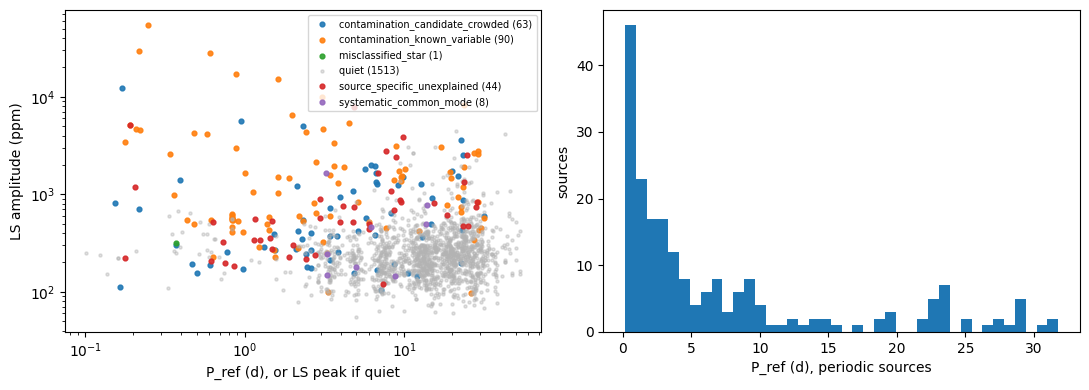

In [8]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 4))
for cls, g in src.groupby("classification"):
    P = g.P_ref_d.where(g.periodic, g.ls_P1_d)
    a0.scatter(P, g.ls_P1_amp_ppm, s=5 if cls == "quiet" else 12, alpha=0.4 if cls == "quiet" else 0.9,
               color="0.7" if cls == "quiet" else None, label=f"{cls} ({len(g)})")
a0.set(xscale="log", yscale="log", xlabel="P_ref (d), or LS peak if quiet", ylabel="LS amplitude (ppm)")
a0.legend(fontsize=7)
src[src.periodic].P_ref_d.plot.hist(bins=40, ax=a1, logx=False)
a1.set(xlabel="P_ref (d), periodic sources", ylabel="sources")
plt.tight_layout()

## Per-file table (needs the drive)

In [9]:
if FILES_CSV.exists():
    files = pd.read_csv(FILES_CSV)   # ~10 s, ~250 MB in memory
    print(files.shape)
    display(files.head())
else:
    files = None
    print(f"Not found: {FILES_CSV}. Plug in the Data_Vault drive (or set SMARTS_DATA_ROOT).")

(1000000, 18)


,file_number,filename,sim_id,noise_tic,classification,periodic,P_ref_d,ls_P1_d,ls_P1_power,ls_P1_amp_ppm,ab_persistent,ls_periodic,search_detected,search_P_d,cm_retained,near_lmc,has_corrupted_segment,ffi_check
0,0,smarts-tess-v1.0-000000.fits,434368,10000259353,quiet,False,NaN,12.13210,0.015419,233.196,True,False,False,NaN,0.319695,False,False,not_tested
1,1,smarts-tess-v1.0-000001.fits,191393,10000455077,quiet,False,NaN,14.55050,0.008940,299.531,True,False,False,NaN,0.419597,False,False,not_tested
2,2,smarts-tess-v1.0-000002.fits,551640,10000275523,quiet,False,NaN,12.05200,0.030049,628.140,True,False,False,NaN,0.322555,True,False,not_tested
3,3,smarts-tess-v1.0-000003.fits,808629,10001717344,contamination_candidate_crowded,True,5.76343,6.26202,0.078443,573.472,True,False,True,5.76343,0.799894,False,False,untestable
4,4,smarts-tess-v1.0-000004.fits,483512,10000455626,quiet,False,NaN,4.96672,0.022209,144.968,True,False,False,NaN,0.803681,False,False,not_tested


In [10]:
if files is not None:
    # Files per class, and the share of the corpus on periodic noise sources
    display(files.classification.value_counts().to_frame("files"))
    print(f"files on periodic noise sources: {files.periodic.sum():,} ({files.periodic.mean():.1%})")

,files
classification,
quiet,878498
contamination_known_variable,53417
contamination_candidate_crowded,35369
source_specific_unexplained,26043
systematic_common_mode,6374
misclassified_star,299


files on periodic noise sources: 121,502 (12.2%)


In [11]:
def lookup(name_or_number=None, sim_id=None):
    """Flags for one SMARTS file, by filename, file number, or SIM_ID."""
    if sim_id is not None:
        return files[files.sim_id == sim_id]
    if isinstance(name_or_number, str):
        return files[files.filename == Path(name_or_number).name]
    return files[files.file_number == name_or_number]

if files is not None:
    display(lookup("smarts-tess-v1.0-000700.fits"))

,file_number,filename,sim_id,noise_tic,classification,periodic,P_ref_d,ls_P1_d,ls_P1_power,ls_P1_amp_ppm,ab_persistent,ls_periodic,search_detected,search_P_d,cm_retained,near_lmc,has_corrupted_segment,ffi_check
700,700,smarts-tess-v1.0-000700.fits,715760,10000425190,contamination_candidate_crowded,True,6.63886,6.46158,0.217536,1335.3,True,True,True,6.63886,1.01269,False,False,untestable


In [12]:
# Join the flags onto your own results table, e.g. one keyed by filename:
# mine = pd.read_csv("my_results.csv")            # needs a 'filename' column
# mine = mine.merge(files, on="filename", how="left")
# quiet_only = mine[~mine.periodic]                # metrics on the quiet subset
if files is not None:
    # Sanity check: the per-file table agrees with the per-source table
    chk = files.drop_duplicates("noise_tic").merge(src, on="noise_tic", suffixes=("", "_src"))
    print("classification consistent:", (chk.classification == chk.classification_src).all())
    print("files per source consistent:",
          (files.noise_tic.value_counts().sort_index() == src.set_index("noise_tic").n_files.sort_index()).all())

classification consistent: True
files per source consistent: True
